#  HDBSCAN (Density-Based Clustering)
**Purpose:** Test whether density-based clustering finds regimes that KMeans cannot, and which days it treats as noise.

**Input:** `data/features/delhi_scaled.csv` (wind direction excluded), `delhi_features.csv`, `delhi_context.csv`

**Outputs:** `data/results/hdbscan_mcs20_ms10_labels.csv`, `data/results/hdbscan_mcs10_ms5_labels.csv`

## 1. Load features
1,195 days × 13 features (wind direction excluded, as in the best KMeans variant).

In [2]:
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import HDBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

BASE = Path.cwd().parent
X = pd.read_csv(BASE / "data" / "features" / "delhi_scaled.csv", parse_dates=["Date"], index_col="Date")
Xn = X.drop(columns=["wind_dir_sin", "wind_dir_cos"])
feat = pd.read_csv(BASE / "data" / "features" / "delhi_features.csv", parse_dates=["Date"], index_col="Date")
ctx = pd.read_csv(BASE / "data" / "features" / "delhi_context.csv", parse_dates=["Date"], index_col="Date")
print(Xn.shape)       

(1195, 13)


## 2. Density check: distance to the 10th nearest day
A smooth curve with no clear elbow means no natural density threshold, which already hints at a continuum of conditions.

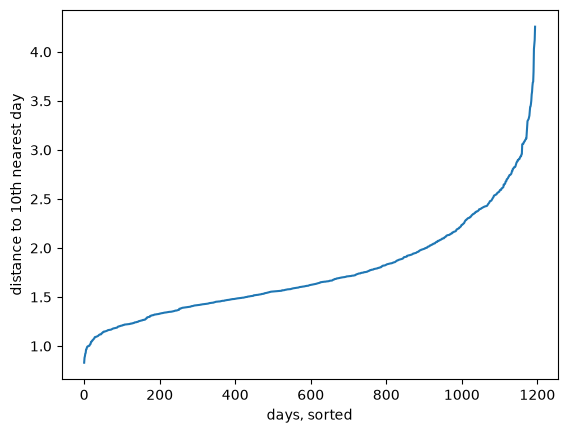

In [3]:
d = np.sort(NearestNeighbors(n_neighbors=10).fit(Xn).kneighbors(Xn)[0][:, -1])
plt.plot(d); plt.xlabel("days, sorted"); plt.ylabel("distance to 10th nearest day"); plt.show()

## 3. Parameter grid
min_cluster_size and min_samples versus number of clusters, noise percentage, and silhouette. Silhouette on high-noise settings is computed on very few points and is not comparable to KMeans.

In [4]:
rows = []
for mcs in [10, 20, 30, 50, 80]:
    for ms in [5, 10, 20]:
        lab = HDBSCAN(min_cluster_size=mcs, min_samples=ms, copy=True).fit_predict(Xn)
        n_cl = len(set(lab)) - (1 if -1 in lab else 0)
        keep = lab != -1
        sil = silhouette_score(Xn[keep], lab[keep]) if n_cl >= 2 else np.nan
        rows.append({"min_cluster_size": mcs, "min_samples": ms, "clusters": n_cl,
                     "noise_%": round((~keep).mean() * 100, 1), "silhouette_no_noise": round(sil, 3)})
print(pd.DataFrame(rows).to_string(index=False))

 min_cluster_size  min_samples  clusters  noise_%  silhouette_no_noise
               10            5         3     13.1                0.054
               10           10         3     19.2                0.043
               10           20         2     83.0                0.460
               20            5         3     13.1                0.054
               20           10         3     74.7                0.107
               20           20         2     83.0                0.460
               30            5         2     44.9                0.064
               30           10         2     76.8                0.344
               30           20         2     83.0                0.460
               50            5         2     71.8                0.378
               50           10         0    100.0                  NaN
               50           20         0    100.0                  NaN
               80            5         2     71.8                0.378
      

## 4. Inspect min_cluster_size=20, min_samples=10
75% of days are labelled noise. Three small pockets appear: a monsoon group (36 days), a winter group (25 days), and a moderate group (241 days). 17 of 21 Diwali-window days are noise.

In [5]:
lab = pd.Series(HDBSCAN(min_cluster_size=20, min_samples=10, copy=True).fit_predict(Xn), index=Xn.index, name="hdb")
print(lab.value_counts().sort_index())
print(pd.crosstab(lab, ctx["month"]))
noise = lab == -1
print("noise days AQI:", ctx.loc[noise, "AQI"].describe().round(0).to_dict())
print("Diwali-window days labelled noise:", int((noise & ctx["diwali_window"]).sum()), "of", int(ctx["diwali_window"].sum()))
print(feat.loc[noise, ["PM2.5", "PM10", "CO", "temp", "wind_speed"]].describe().round(1))

hdb
-1    893
 0     25
 1    241
 2     36
Name: count, dtype: int64
month  1   2   3    4    5   6   7   8   9   10  11  12
hdb                                                    
-1     76  78  89  103  113  86  51  47  55  64  61  70
 0     13   0   0    0    0   0   0   0   0   0   4   8
 1     34  32  35   17   11  10   1   0   1  29  25  46
 2      0   0   0    0    0   1  11  15   9   0   0   0
noise days AQI: {'count': 893.0, 'mean': 247.0, 'std': 119.0, 'min': 51.0, '25%': 142.0, '50%': 237.0, '75%': 334.0, 'max': 677.0}
Diwali-window days labelled noise: 17 of 21
       PM2.5   PM10     CO   temp  wind_speed
count  893.0  893.0  893.0  893.0       893.0
mean   112.5  229.2    1.1   24.9        16.3
std     81.2  122.8    0.5    7.1         5.1
min     10.2   19.5    0.1    6.9         5.5
25%     54.9  133.0    0.8   18.5        12.1
50%     91.2  209.0    1.0   26.7        16.0
75%    150.8  303.8    1.4   30.3        19.7
max    639.2  796.9    3.7   37.9        31.8


## 5. Lowest-noise setting and comparison with KMeans
Profiles of the HDBSCAN groups and a crosstab against the KMeans clusters.

In [6]:
lab2 = pd.Series(HDBSCAN(min_cluster_size=10, min_samples=5, copy=True).fit_predict(Xn), index=Xn.index, name="hdb")
raw = feat.drop(columns=["wind_dir_sin", "wind_dir_cos"])
prof = raw.groupby(lab2).mean().round(1)
prof["days"] = lab2.value_counts().sort_index()
print(prof.T)
print(pd.crosstab(lab2, ctx["month"]))

# compare with KMeans
km = pd.read_csv(BASE / "data" / "results" / "kmeans_labels.csv", parse_dates=["Date"], index_col="Date")["kmeans_cluster"]
print(pd.crosstab(lab2, km))

# save both settings for the comparison notebook
(BASE / "data" / "results").mkdir(parents=True, exist_ok=True)
lab.to_csv(BASE / "data" / "results" / "hdbscan_mcs20_ms10_labels.csv")
lab2.to_csv(BASE / "data" / "results" / "hdbscan_mcs10_ms5_labels.csv")

hdb            -1      0      1      2
PM2.5       126.1   92.5  118.8  128.3
PM10        258.6  146.1  230.5  327.3
NO           41.0   28.4   38.6   71.6
NO2          53.5   28.2   47.3   79.6
NH3          42.4   44.5   40.8   40.6
SO2          20.3   10.7   15.0   43.1
O3           40.8   34.8   42.3   40.8
CO            0.9    0.3    1.3    0.9
Benzene       3.0    0.5    3.8    3.3
PM_ratio      0.5    0.6    0.5    0.4
temp         25.4   28.2   23.2   32.1
rain          3.4    0.0    1.1    0.1
wind_speed   20.0   12.2   14.7   18.3
days        156.0   20.0  995.0   24.0
month   1    2    3   4   5   6   7   8   9   10  11   12
hdb                                                      
-1      22    7   24  26  34  17   1   4   4   4   8    5
 0       0    0    0   0   0   0   0   0   5  15   0    0
 1     101  103  100  84  77  79  62  58  56  74  82  119
 2       0    0    0  10  13   1   0   0   0   0   0    0
kmeans_cluster    0    1    2    3    4
hdb                        

## Conclusion
HDBSCAN treats most days as noise (45-100% depending on settings; 75% at min_cluster_size=20, min_samples=10).
The only clearly separated group is the monsoon washout (July-September).
Diwali days are not isolated (17 of 21 are labelled noise). This supports the picture of a continuum of conditions rather than sharply separated regimes.